# Klasifikasi Gambar Dokumen dengan ResNet50

Alur: pemeriksaan dataset → EDA → split validasi stratified → fine-tuning ResNet50 → evaluasi → prediksi dan ekspor submission. Aktifkan GPU di runtime/lingkungan jika tersedia. Model pretrained mengunduh bobot ImageNet saat pertama kali dijalankan.

In [1]:
from pathlib import Path
import os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tqdm.auto import tqdm
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
import sys
sys.path.insert(0, str(ROOT))
from scripts.data import DocumentDataset, resolve_image_path
DATA_DIR = ROOT / 'dataset'
OUT_DIR = ROOT / 'submissions'; OUT_DIR.mkdir(exist_ok=True)
CKPT_DIR = ROOT / 'checkpoints'; CKPT_DIR.mkdir(exist_ok=True)
best_path = CKPT_DIR / 'resnet50_best.pth'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
if DEVICE.type == 'cuda': print('GPU:', torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Muat data dan cek struktur
Pastikan direktori dataset telah diekstrak seperti dijelaskan dalam README.

In [2]:
train_df = pd.read_csv(DATA_DIR / 'train.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')
sample_sub = pd.read_csv(DATA_DIR / 'sample_submission.csv')
display(train_df.head(), test_df.head(), sample_sub.head())
print('Train:', train_df.shape, '| Test:', test_df.shape)
print('Classes:', train_df['class_name'].nunique())
print('Missing values:\n', train_df.isna().sum())
assert {'filename','label','class_name'}.issubset(train_df.columns)
assert 'filename' in test_df.columns
assert len(sample_sub) == len(test_df)

,id,filename,class_name,label
0,train_00001,train/resume/50497291-7292.tif,resume,12
1,train_00002,train/scientific_publication/50728670-8670.tif,scientific_publication,13
2,train_00003,train/scientific_report/87112192.tif,scientific_report,14
3,train_00004,train/scientific_publication/10343650_10343655...,scientific_publication,13
4,train_00005,train/specification/2057960699_2057960701.tif,specification,15


,id,filename
0,test_00001,test/test_00001.tif
1,test_00002,test/test_00002.tif
2,test_00003,test/test_00003.tif
3,test_00004,test/test_00004.tif
4,test_00005,test/test_00005.tif


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,0
3,test_00004,0
4,test_00005,0


Train: (32003, 4) | Test: (7994, 2)
Classes: 16
Missing values:
 id            0
filename      0
class_name    0
label         0
dtype: int64


,jumlah
class_name,
scientific_publication,2056
resume,2029
handwritten,2026
file_folder,2022
email,2013
advertisement,2012
form,2005
budget,2004
scientific_report,1999


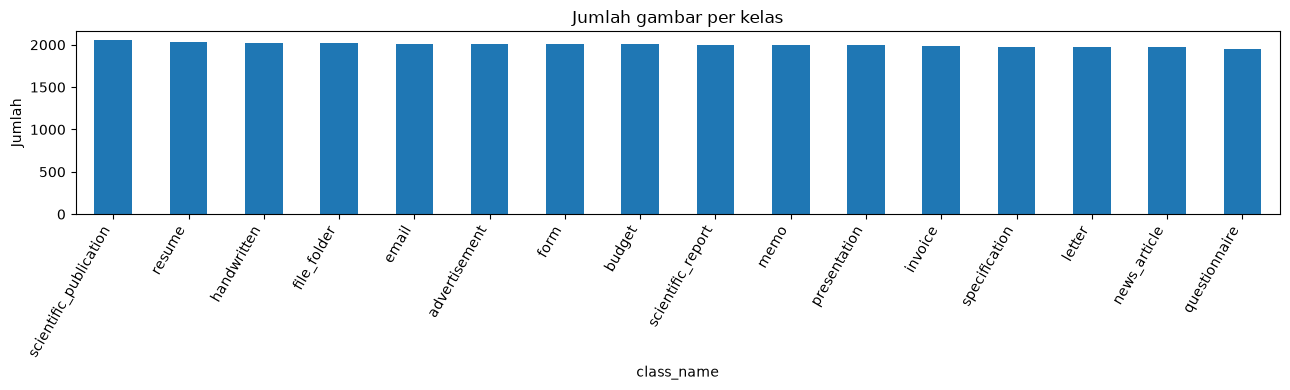

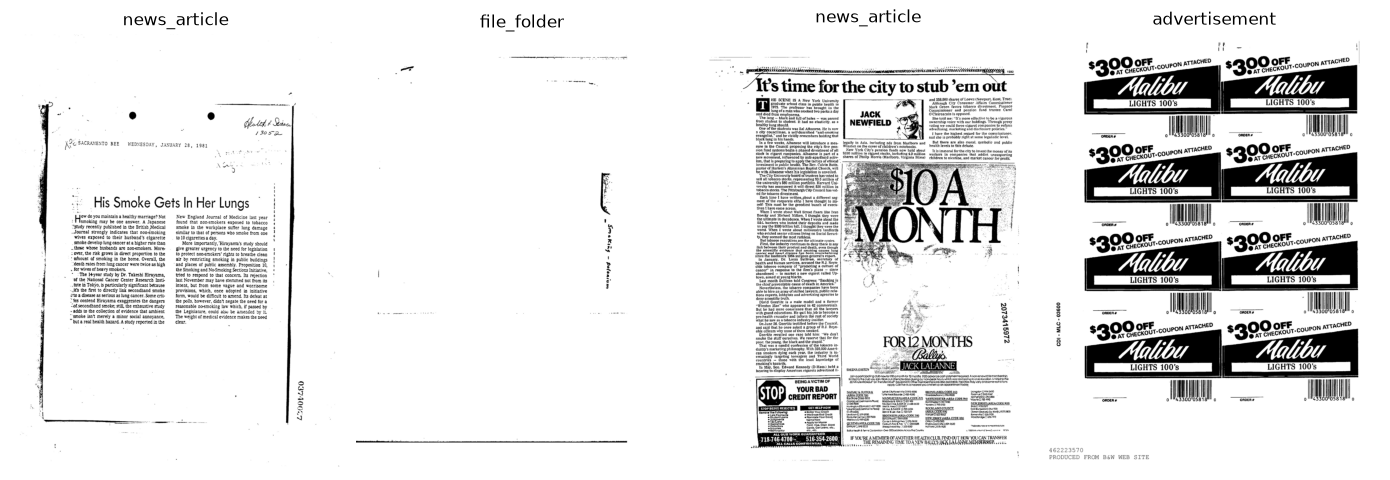

In [3]:
class_counts = train_df['class_name'].value_counts().sort_values(ascending=False)
display(class_counts.to_frame('jumlah'))
class_counts.plot(kind='bar', figsize=(13,4), title='Jumlah gambar per kelas')
plt.ylabel('Jumlah'); plt.xticks(rotation=60, ha='right'); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 4, figsize=(14, 5))
for ax, (_, row) in zip(axes, train_df.sample(min(4, len(train_df)), random_state=SEED).iterrows()):
    img = Image.open(resolve_image_path(row['filename'], DATA_DIR)).convert('RGB')
    ax.imshow(img); ax.set_title(row['class_name']); ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Split validasi dan transformasi
Pembagian stratified mempertahankan proporsi kelas. Resolusi 224×224 sesuai input standar ResNet; normalisasi mengikuti statistik ImageNet.

In [4]:
classes = sorted(train_df['class_name'].unique().tolist())
class_to_idx = {name: i for i, name in enumerate(classes)}
idx_to_class = {i: name for name, i in class_to_idx.items()}
# Gunakan label kompetisi sebagai target agar output CSV sesuai format Kaggle.
label_values = sorted(train_df['label'].unique().tolist())
label_to_idx = {label: i for i, label in enumerate(label_values)}
idx_to_label = {i: label for label, i in label_to_idx.items()}
train_df['target'] = train_df['label'].map(label_to_idx)
train_part, val_part = train_test_split(train_df, test_size=0.15, random_state=SEED, stratify=train_df['target'])
print('Train:', len(train_part), 'Validasi:', len(val_part), 'Kelas:', len(label_values))
IMG_SIZE = 224
train_tfms = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.RandomRotation(3), transforms.ColorJitter(brightness=0.12, contrast=0.12), transforms.ToTensor(), transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
eval_tfms = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])


Train: 27202 Validasi: 4801 Kelas: 16


In [5]:
BATCH_SIZE = 16
NUM_WORKERS = 1  # Satu worker mempercepat TIFF tanpa menyalin PyTorch ke banyak proses.
train_loader = DataLoader(DocumentDataset(train_part, train_tfms, DATA_DIR), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=DEVICE.type=='cuda')
val_loader = DataLoader(DocumentDataset(val_part, eval_tfms, DATA_DIR), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=DEVICE.type=='cuda')
test_loader = DataLoader(DocumentDataset(test_df, eval_tfms, DATA_DIR, labeled=False), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=DEVICE.type=='cuda')
xb, yb = next(iter(train_loader)); print('Batch:', xb.shape, yb.shape)

Batch: torch.Size([16, 3, 224, 224]) torch.Size([16])


## 3. ResNet50 dan loop training
Gunakan bobot ImageNet dan fine-tuning seluruh jaringan. Mixed precision aktif khusus pada CUDA untuk mempercepat training dan menghemat memori.

In [6]:
try:
    weights = models.ResNet50_Weights.DEFAULT
    model = models.resnet50(weights=weights)
except Exception as exc:
    print('Bobot pretrained tidak dapat dimuat; memakai inisialisasi acak:', exc)
    model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(label_values))
model = model.to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=2, factor=0.5)
scaler = torch.amp.GradScaler('cuda', enabled=DEVICE.type=='cuda')
EPOCHS = 0 if best_path.exists() else 2
# Lanjutkan dari checkpoint yang tersimpan; training baru berjalan jika belum ada checkpoint.
if best_path.exists():
    previous = torch.load(best_path, map_location=DEVICE)
    model.load_state_dict(previous['model_state_dict'])
    print('Melanjutkan dari checkpoint:', best_path)

Melanjutkan dari checkpoint: C:\Users\Akmal sharif Ramdan\Documents\Tugas2_SML\checkpoints\resnet50_best.pth


In [7]:
def run_epoch(loader, training):
    model.train(training); total_loss = 0.0; all_preds = []; all_targets = []
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for batch in tqdm(loader, leave=False):
            if training: images, targets = batch
            else: images, targets = batch
            images = images.to(DEVICE, non_blocking=True); targets = targets.to(DEVICE, non_blocking=True)
            if training: optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type=='cuda'):
                logits = model(images); loss = criterion(logits, targets)
            if training:
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            total_loss += loss.item() * images.size(0)
            all_preds.extend(logits.argmax(1).detach().cpu().tolist()); all_targets.extend(targets.cpu().tolist())
    return total_loss / len(loader.dataset), accuracy_score(all_targets, all_preds), all_targets, all_preds

history = []; best_acc = -1.0; best_path = CKPT_DIR / 'resnet50_best.pth'
for epoch in range(EPOCHS):
    start = time.time()
    train_loss, train_acc, _, _ = run_epoch(train_loader, True)
    val_loss, val_acc, y_true, y_pred = run_epoch(val_loader, False)
    scheduler.step(val_acc)
    history.append({'epoch':epoch+1,'train_loss':train_loss,'train_acc':train_acc,'val_loss':val_loss,'val_acc':val_acc})
    print(f'Epoch {epoch+1:02d}/{EPOCHS} | train loss {train_loss:.4f} acc {train_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f} | {time.time()-start:.0f}s')
    if val_acc > best_acc:
        best_acc = val_acc; torch.save({'model_state_dict':model.state_dict(),'classes':classes,'label_values':label_values}, best_path)
        print('Checkpoint terbaik disimpan:', best_path)

In [8]:
history_df = pd.DataFrame(history)
if not history_df.empty:
    display(history_df)
    fig, axes = plt.subplots(1, 2, figsize=(11,4))
    history_df.plot(x='epoch', y=['train_loss','val_loss'], ax=axes[0], title='Loss')
    history_df.plot(x='epoch', y=['train_acc','val_acc'], ax=axes[1], title='Accuracy')
    plt.tight_layout(); plt.show()
else:
    print('Training dilewati karena checkpoint tersedia.')
checkpoint = torch.load(best_path, map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
val_loss, val_acc, y_true, y_pred = run_epoch(val_loader, False)
print(f'Best validation accuracy: {val_acc:.4f} | loss: {val_loss:.4f}')
print(classification_report(y_true, y_pred, target_names=[str(x) for x in label_values], zero_division=0))

Training dilewati karena checkpoint tersedia.


  0%|          | 0/301 [00:02<?, ?it/s]

Best validation accuracy: 0.8217 | loss: 0.6172
              precision    recall  f1-score   support

           0       0.87      0.88      0.88       302
           1       0.81      0.70      0.75       301
           2       0.97      0.96      0.96       302
           3       0.82      0.97      0.89       303
           4       0.64      0.64      0.64       301
           5       0.93      0.92      0.92       304
           6       0.75      0.88      0.81       297
           7       0.89      0.85      0.87       296
           8       0.88      0.87      0.88       299
           9       0.81      0.80      0.81       296
          10       0.71      0.72      0.71       299
          11       0.80      0.73      0.76       292
          12       0.98      0.86      0.92       304
          13       0.83      0.90      0.86       308
          14       0.59      0.62      0.61       300
          15       0.90      0.85      0.88       297

    accuracy                    

## 4. Prediksi test dan submission Kaggle
Kolom prediksi diambil dari `sample_submission.csv` agar urutan dan nama kolom persis mengikuti format kompetisi.

In [9]:
model.eval(); test_pred_idx = []
with torch.no_grad():
    for images in tqdm(test_loader):
        images = images.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type=='cuda'):
            logits = model(images)
        test_pred_idx.extend(logits.argmax(1).cpu().tolist())
predicted_labels = [idx_to_label[i] for i in test_pred_idx]
submission = sample_sub.copy()
target_col = 'label'
assert 'id' in test_df.columns and 'id' in sample_sub.columns
assert len(predicted_labels) == len(test_df) == len(sample_sub)
submission = pd.DataFrame({'id': test_df['id'].values, 'label': predicted_labels})
submission_path = OUT_DIR / 'submission.csv'
submission.to_csv(submission_path, index=False)
print('Tersimpan:', submission_path, '| shape:', submission.shape, '| kolom:', submission.columns.tolist())
display(submission.head())

  0%|          | 0/500 [00:02<?, ?it/s]

Tersimpan: C:\Users\Akmal sharif Ramdan\Documents\Tugas2_SML\submissions\submission.csv | shape: (7994, 2) | kolom: ['id', 'label']


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,6
3,test_00004,6
4,test_00005,13
